# 11. 流式执行
## 11.1. 概述
### 11.1.1 什么是流式执行
**流式执行（`Streaming Execution`）**，是指程序在任务尚未全部完成时，就将执行过程中已经产生的中间结果、状态变化或事件持续输出给调用方，而不是等待整个任务结束后一次性返回最终结果。

简而言之：流式执行就是

> 边执行、边产生事件、边向调用方返回结果。

### 11.1.2 什么是`LangGraph`的流式执行
**`LangGraph`** 的流式执行是指，状态图计算过程中，将节点输出、状态更新、消息增量、自定义事件或调试信息等写入流式队列，并在特定的时机将流式队列中的信息返还给调用者。

在同步执行中，这些数据最终进入内部的**同步流式队列**；在异步执行中，则进入对应的**异步队列**。调用方通过**迭代器**逐条消费这些数据，因此不必等到整张图执行完毕后再获得反馈。

### 11.1.3 相关API概述
针对同步和异步:

1. `stream/astream`

调用方通过 **`stream_mode`** 选择需要消费的内容，例如状态、节点更新、模型消息、自定义数据、检查点或任务事件。这是本章的重点。

**`stream`与`astream`的区别**

| 维度       | `stream()`                                | `astream()`                                      |
| :--------- | :---------------------------------------- | :----------------------------------------------- |
| 调用方式   | 同步迭代 `for chunk in graph.stream(...)` | 异步迭代 `async for chunk in graph.astream(...)` |
| 运行环境   | 普通 Python 脚本                          | `asyncio` 事件循环（Jupyter、FastAPI 等）        |
| 参数与输出 | 相同 `stream_mode`，语义一致              | 相同 `stream_mode`，语义一致                     |
| 适用场景   | 同步批处理、CLI 工具                      | `async` 服务端、结合其他异步 IO                  |

2. `astream_events`

获取图运行过程中产生的 **`Runnable`** 标准事件（组件生命周期、父子调用关系、输入输出等）。

## 11.2 stream/astream
二者使用相同的流模式，且在参数一致时，输出数据的语义和封装格式一致；区别主要在于调用方分别使用同步迭代和异步迭代进行消费。

前面的章节我们都是通过 **`invoke`** 调用状态图。实际上，**`invoke`** 会在内部消费 **`stream`**，并把流式执行结果汇总为最终返回值；**`ainvoke`** 与 **`astream`** 的关系同理。

函数签名如下:

1. 同步版:
```python
stream(
  self,
  input: InputT | Command | None,
  config: RunnableConfig | None = None,
  *,
  context: ContextT | None = None,
  stream_mode: StreamMode | Sequence[StreamMode] | None = None,
  print_mode: StreamMode | Sequence[StreamMode] = (),
  output_keys: str | Sequence[str] | None = None,
  interrupt_before: All | Sequence[str] | None = None,
  interrupt_after: All | Sequence[str] | None = None,
  durability: Durability | None = None,
  control: RunControl | None = None,
  subgraphs: bool = False,
  debug: bool | None = None,
  version: Literal['v1', 'v2'] = 'v1',
  **kwargs: Unpack[DeprecatedKwargs]
) -> Iterator[dict[str, Any] | Any]
```

2. 异步版:

```python
astream(
  self,
  input: InputT | Command | None,
  config: RunnableConfig | None = None,
  *,
  context: ContextT | None = None,
  stream_mode: StreamMode | Sequence[StreamMode] | None = None,
  print_mode: StreamMode | Sequence[StreamMode] = (),
  output_keys: str | Sequence[str] | None = None,
  interrupt_before: All | Sequence[str] | None = None,
  interrupt_after: All | Sequence[str] | None = None,
  durability: Durability | None = None,
  control: RunControl | None = None,
  subgraphs: bool = False,
  debug: bool | None = None,
  version: Literal['v1', 'v2'] = 'v1',
  **kwargs: Unpack[DeprecatedKwargs]
) -> AsyncIterator[dict[str, Any] | Any]
```

### 11.2.1 `stream` / `astream` 参数与返回值

以下说明按本项目当前安装的 **LangGraph 1.2.16** 核对。两种方法的参数含义相同；`self` 是编译后的图实例，由 Python 自动传入。签名中的 `*` 表示后续参数必须按名称传入，例如 `stream_mode="updates"`。

#### 11.2.1.1 参数说明

| 参数 | 类型 / 默认值 | 含义与用法 |
| :--- | :--- | :--- |
| `input` | `InputT`、`Command` 或 `None`；必填 | 本次执行的输入。对于本章的 `StateGraph`，通常是符合输入 schema 的状态字典，如 `{"initial_state": "初始状态"}`；`Command(resume=...)` 用于向动态中断传入恢复值；`None` 可用于从已有检查点继续执行，例如恢复静态断点。后两种恢复方式需要相应的检查点和线程配置。 |
| `config` | `RunnableConfig`；`None` | 执行配置，例如 `{"configurable": {"thread_id": "demo"}, "recursion_limit": 50, "tags": ["stream-demo"]}`。`thread_id` 用于定位持久化线程；`recursion_limit` 限制图执行的超步数；还可设置 `callbacks`、`metadata` 等。未传时会合并图已有配置与运行时默认配置。 |
| `context` | `ContextT`；`None` | 本次运行的静态上下文，例如用户身份、数据库连接等依赖。其结构对应建图时的 `context_schema`，节点通过 `Runtime[ContextT]` 的 `runtime.context` 读取。它不作为状态字段参与节点更新或 reducer 合并。 |
| `stream_mode` | `StreamMode` 或模式序列；`None` | 选择迭代器产出的内容，例如 `"updates"`、`"values"`、`"messages"`，或 `["updates", "messages"]`。`None` 使用图实例的默认模式；本章普通 `StateGraph(...).compile()` 默认是 `"updates"`。作为另一张图的节点被调用时，未显式指定模式的嵌套调用会默认使用 `"values"`。各模式见 11.2.2。 |
| `print_mode` | `StreamMode` 或模式序列；`()` | 将指定模式的数据打印到控制台，默认不额外打印。例如 `stream_mode="messages", print_mode="updates"` 表示迭代消费模型消息，同时在控制台查看节点更新。它不改变迭代器选择输出的模式和封装格式。 |
| `output_keys` | `str` 或字段名序列；`None` | 选择要输出的状态通道（本章通常对应状态字段），如 `["node_a_output"]`。默认使用图的流式通道，普通状态图通常包含所有非上下文字段。主要影响 `values`、`updates` 等状态输出，不改变节点实际读写的状态，也不是按节点名或 LLM token 筛选。`values` 中传单个字符串会直接输出该字段的值，传列表则保留字典结构。 |
| `interrupt_before` | `"*"` 或节点名序列；`None` | 在指定节点执行**前**设置静态断点，例如 `["node_b"]`；`"*"` 表示所有节点。`None` 沿用 `compile()` 时的设置，编译时未设置则不在节点前中断。 |
| `interrupt_after` | `"*"` 或节点名序列；`None` | 在指定节点执行**后**设置静态断点。取值与默认规则同 `interrupt_before`。需要跨调用恢复时，应配置 checkpointer，并在恢复时使用相同的 `thread_id`。 |
| `durability` | `"sync"`、`"async"` 或 `"exit"`；`None` | 控制**检查点持久化时机**：`"sync"` 在下一超步开始前完成保存；`"async"` 在下一超步执行期间异步保存；`"exit"` 在本次图执行退出时保存，包括正常结束、异常或中断。`None` 继承配置，否则通常使用 `"async"`。只有配置了 checkpointer 才有持久化效果；它与使用 `stream` 还是 `astream` 无关。 |
| `control` | `RunControl`；`None` | 可选的运行控制对象，从 `langgraph.runtime` 导入。外部可通过 `control.request_drain()` 请求协作式收尾（drain），由运行时在安全边界处理。它不强制取消正在执行的节点，也不同于人工审批中断。通常不必传；如手动创建，应每次运行使用新对象。 |
| `subgraphs` | `bool`；`False` | 是否同时输出子图内部事件。`False` 时只消费当前图的流；`True` 时包含子图事件，并通过命名空间标识来源。`v1` 会改变外层元组形状，`v2` 通过 `ns` 字段表示，见下文。 |
| `debug` | `bool`；`None` | 调试打印开关。本版本中，调用时传 `True` 或图自身开启了调试，会打印 `updates`、`values`。它不等于 `stream_mode="debug"`：后者将调试事件交给迭代器消费。若编译图时已开启调试，仅在本次调用传 `False` 不会关闭图自身的调试设置。 |
| `version` | `"v1"` 或 `"v2"`；`"v1"` | 控制 chunk 的**外层封装格式**。`v1` 根据单模式 / 模式列表及 `subgraphs` 返回原始数据或元组；`v2` 使用统一的 `StreamPart` 字典。这里的版本属于 `stream` / `astream`，不要与 `astream_events` 的事件协议版本混用。 |
| `**kwargs` | `Unpack[DeprecatedKwargs]`；默认不传 | 为旧参数保留的兼容入口，不是任意业务参数的传递通道。例如旧参数 `checkpoint_during` 已弃用，应改用 `durability`，不要同时传入二者。业务输入放在 `input`，运行依赖放在 `context`。 |

注意区分三个入口：**`input` 是图要处理的数据，`config` 是如何执行，`context` 是执行时可用的静态依赖**。使用检查点的典型配置为：

```python
config = {"configurable": {"thread_id": "stream-demo"}}
# graph 应已通过 builder.compile(checkpointer=...) 编译。
# 动态中断恢复：graph.stream(Command(resume="用户的选择"), config=config, ...)
# 静态断点恢复：graph.stream(None, config=config, ...)
```

#### 11.2.1.2 返回值：先区分迭代器与 chunk

- **`stream(...)` 返回同步迭代器**，类型为 `Iterator[...]`，用 `for` 消费。
- **`astream(...)` 返回异步迭代器**，类型为 `AsyncIterator[...]`，用 `async for` 消费；不需要先写 `await graph.astream(...)`。
- 每次迭代得到一个 **chunk**。它可能是状态、节点更新、消息片段或事件，不保证是字符串，也不保证一块对应一个节点或一个 token。图在迭代消费过程中推进执行，异常也可能在迭代时抛出。
- 签名中的 `Any` 表示 payload 随流模式变化，不能仅凭 `Iterator[dict[str, Any] | Any]` 判断每块数据的结构。

**（1）`version="v1"`：外层格式由调用参数决定**

下表中的 `data` 表示模式本身的数据；这里的模式序列以通常使用的 **列表** 为例。

| `stream_mode` | `subgraphs` | 每个 chunk 的结构 |
| :--- | :--- | :--- |
| 单个字符串，如 `"updates"` | `False` | `data` |
| 列表，如 `["updates"]` 或 `["updates", "messages"]` | `False` | `(mode, data)` |
| 单个字符串 | `True` | `(namespace, data)` |
| 列表 | `True` | `(namespace, mode, data)` |

**即使列表里只有一个模式，`["updates"]` 与 `"updates"` 的外层结构也不同。** 后文示例使用 `stream_mode=["values"]`，所以会输出 `("values", 状态字典)`。

`namespace` 是路径元组：当前根图为 `()`，子图可能为 `("parent_node:<task_id>",)`，更深层子图会继续追加路径元素。它用于区分事件来自哪一层图。

以 `updates` 模式、节点 `node_a` 的输出为例：

```python
# stream_mode="updates", subgraphs=False
{"node_a": {"node_a_output": "节点A的输出"}}

# stream_mode=["updates"], subgraphs=False
("updates", {"node_a": {"node_a_output": "节点A的输出"}})

# stream_mode=["updates"], subgraphs=True：根图事件的 namespace 为 ()
((), "updates", {"node_a": {"node_a_output": "节点A的输出"}})
```

**（2）`version="v2"`：统一使用 `StreamPart` 字典**

无论选择单模式、模式列表，还是开启子图输出，每块都有以下公共字段：

```python
{
    "type": "updates",   # 该块所属的流模式
    "ns": (),            # 来源命名空间；子图事件包含子图路径
    "data": {"node_a": {"node_a_output": "节点A的输出"}},
}
```

`data` 的结构仍由流模式决定。特别地，本地 1.2.16 的 `values` 块还包含 `interrupts` 字段（`tuple[Interrupt, ...]`，无中断时为 `()`）；中断信息从原始 payload 的 `__interrupt__` 中移到该字段，因此不要假设所有模式都只有三个字段。

**（3）模式决定内层 `data` 的含义**

| 模式 | `data` 的典型结构 | 阅读要点 |
| :--- | :--- | :--- |
| `values` | `{"initial_state": "初始状态", "node_a_output": "节点A的输出"}` | 本章状态图在每个超步后输出状态快照，也可能先输出初始状态；有 `output_keys` 时仅输出所选通道。 |
| `updates` | `{"node_a": {"node_a_output": "节点A的输出"}}` | 外层通常是节点名，内层是节点返回的更新；同一超步中的多个节点更新分别输出。这些是待合并的更新，不一定等于 reducer 合并后的最终字段值。 |
| `messages` | `(message_chunk, metadata)` | 模型生成的消息片段及调用元数据，如 `metadata["langgraph_node"]`；消息片段通常是 `AIMessageChunk`，可以读取 `.content`。它不要求状态中存在名为 `messages` 的字段；应通过元数据筛选节点。 |
| `custom` | 节点通过 `StreamWriter` 写出的任意数据 | 可以是字典、字符串等，例如 `{"progress": 50}`。 |
| `checkpoints` | 包含 `values`、`next`、`config`、`metadata`、`tasks` 等字段的事件字典 | 描述检查点快照，需要配置 checkpointer；不是检查点存储器内部的原始序列化数据。 |
| `tasks` | 包含任务标识、节点名以及输入或结果 / 错误等信息的事件字典 | 区分任务开始与结束，具体字段随事件阶段变化。 |
| `debug` | 包含 `type`、`timestamp`、`step`、`payload` 等字段的事件字典 | 这是调试事件自身的结构；使用 `v2` 时，它仍放在 `StreamPart["data"]` 中，不要与外层 `type` 混淆。 |

例如 `v1` 的 `stream_mode=["messages"]` 会得到 `("messages", (message_chunk, metadata))`，需要先解包模式，再解包消息；`v2` 则直接从 `chunk["data"]` 解包消息。

#### 11.2.1.3 消费示例

下面假设 `graph` 是后文示例中已经编译好的状态图，展示相同输入的不同消费方式：

```python
inputs = {"initial_state": "初始状态"}

# v1：单个模式，直接得到节点更新。
for data in graph.stream(inputs, stream_mode="updates"):
    print(data)

# v1：模式列表，先解包 (mode, data)。
for mode, data in graph.stream(inputs, stream_mode=["values", "updates"]):
    print(mode, data)

# v2：外层结构统一，按字段读取。
for chunk in graph.stream(inputs, stream_mode=["values", "updates"], version="v2"):
    print(chunk["type"], chunk["ns"], chunk["data"])

# 异步版在 Jupyter 中可直接使用 async for；普通脚本需放入 async def 中运行。
async for chunk in graph.astream(inputs, stream_mode="updates", version="v2"):
    print(chunk["data"])
```

参考：[官方流式输出指南](https://docs.langchain.com/oss/python/langgraph/streaming)、[`Pregel.stream` API](https://reference.langchain.com/python/langgraph/pregel/main/Pregel/stream)。参数默认行为与 `values.interrupts` 的细节以本项目安装的 `langgraph/pregel/main.py` 实现为准。


### 11.2.2 stream_mode
流式输出支持不同的输出模式 **`stream_mode`**，这规定了流式输出的内容（在 **`LangGraph`** 中称为 **`chunk`**）。**`stream_mode`** 可传入单个字符串或模式列表。

| 模式              | 输出内容                                                 | 适用场景             |
| :---------------- | :------------------------------------------------------- | :------------------- |
| **`values`**      | 每个超步后的完整状态                                     | 需要完整状态快照     |
| **`updates`**     | 节点产生的状态更新（增量）                               | 只关心节点输出变化   |
| **`messages`**    | LLM 消息片段及元数据 `(message_chunk, metadata)`                            | LLM 对话流式输出     |
| **`checkpoints`** | 检查点更新事件（需检查点存储器）                         | 持久化监控、中断调试 |
| **`tasks`**       | 任务开始/结果事件（含触发通道、异常）                    | 运行时观测、任务追踪 |
| **`debug`**       | `checkpoints` + `tasks` 的统一封装，附加超步编号、时间戳 | 调试排错             |
| **`custom`**      | 节点/工具通过 `stream_writer` 主动写出的自定义数据       | 进度通知、阶段说明   |

#### 11.2.2.1 `values`

('values', {'initial_state': '初始状态'})

('values', {'initial_state': '初始状态', 'node_a_output': '节点A的输出'})

('values', {'initial_state': '初始状态', 'node_a_output': '节点A的输出', 'node_b_output': '节点B的输出'})

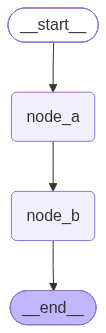

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from rich import print as rprint
class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["values"],# 这里使用了列表输入，所以输出的会是元组
):
    rprint(chunk)

from IPython.display import display
display(graph)

#### 11.2.2.2 `updates`

In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["updates"],
):
    print(chunk)

('updates', {'node_a': {'node_a_output': '节点A的输出'}})
('updates', {'node_b': {'node_b_output': '节点B的输出'}})


#### 11.2.2.3 `messages`

messages 模式下的输出结果是一个元组，其结构如下： (message_chunk, metadata)

* message_chunk ：这是来自大语言模型的token或消息片段。
* metadata ：这是一个包含有关图节点和 LLM 调用信息的字典。

**实际输出解读**

以下结合下方第一个流式案例保存的输出，说明 `message_chunk` 与 `metadata` 中的内容。

**1. `AIMessageChunk`：模型生成过程中的消息片段**

本例中的 `message_chunk` 是 `AIMessageChunk` 对象。它的 `content` 表示本次新增的内容，各个正文片段依次为：

```text
"你好" → "！" → "有什么" → "可以" → "帮" → "你" → "？"
```

按顺序拼接后，得到完整回答：`你好！有什么可以帮你？`。每块只包含本次新增的内容，不会重复携带此前已经生成的正文。一个 chunk 不保证对应一个字或一个 token，例如 `"有什么"` 在本次输出中就是一个片段；因此 chunk 的数量不等于 token 用量。

消息对象中各字段的含义如下：

| 字段 | 本例中的含义 |
| :--- | :--- |
| `content` | 当前新增的正文；也可能为空字符串。 |
| `id` | 消息标识。本次回答的各个片段使用相同的 ID，最后完整的 `AIMessage` 也沿用该 ID。 |
| `additional_kwargs` | 消息的扩展信息，本次各片段中为 `{}`。 |
| `response_metadata` | 模型响应信息，例如 `model_provider`、`model_name`、`finish_reason` 和 `service_tier`；并非每块都包含全部字段。 |
| `usage_metadata` | token 用量统计，本次在一个靠后的空内容片段中出现。 |
| `tool_calls` / `tool_call_chunks` | 已解析的工具调用 / 工具调用增量片段，本例均为 `[]`，没有工具调用。 |
| `invalid_tool_calls` | 未能正确解析的工具调用，本例为 `[]`。 |
| `chunk_position` | 消息片段的位置标记，本次最后一块为 `"last"`。 |

**2. `content=""`：没有正文，但仍可能携带信息**

本次保存的输出共有 11 个 `messages` 片段，其中 7 个包含正文，另外 4 个的 `content` 为空：

| 出现位置 | 携带的信息 | 如何理解 |
| :--- | :--- | :--- |
| 第一个片段 | `response_metadata={"model_provider": "openai"}` | 尚无正文，仅包含模型提供方等信息。 |
| 正文之后 | `response_metadata` 中有 `finish_reason="stop"` | 模型此次生成正常停止；同一块还带有模型名称和服务层级等信息。 |
| 随后一个片段 | `usage_metadata` | 携带此次调用的 token 用量统计。 |
| 最后一个片段 | `chunk_position="last"` | 标识这条消息流的最后一个片段。 |

其中用量统计为：

```python
{
    "input_tokens": 8,
    "output_tokens": 34,
    "total_tokens": 42,
    "input_token_details": {"audio": 0, "cache_read": 0},
    "output_token_details": {"audio": 0, "reasoning": 0},
}
```

这些数值是本次调用报告的用量，不能通过正文片段数量推算。`content` 为空本身不表示出错，也不能单凭空内容判定生成已经结束；需要结合结束原因或末块标记。仅展示回答文字时，可以跳过空内容；需要记录用量、结束原因或工具调用时，还应读取相应字段。片段的数量、边界和元数据分布可能随模型集成、版本及实际响应变化。

**3. `metadata`：消息来自哪个节点、哪次执行**

与消息对象一起输出的 `metadata` 描述图执行及模型调用的来源。它与 `message_chunk.response_metadata` 含义不同：前者帮助定位调用，后者描述模型响应。

| 字段 | 本次输出 / 含义 |
| :--- | :--- |
| `langgraph_node` | `"llm_node"`，表示产生该消息的节点；可用于筛选指定节点的消息。 |
| `langgraph_step` | `1`，表示节点所在的执行超步；不是消息片段序号或 token 序号。 |
| `langgraph_triggers` | `("branch:to:llm_node",)`，表示触发节点执行的内部通道。 |
| `langgraph_path` | `("__pregel_pull", "llm_node")`，表示内部任务执行路径，主要用于调试。 |
| `langgraph_checkpoint_ns` / `checkpoint_ns` | 本次任务的检查点命名空间，值中包含节点名与任务标识；出现这些字段不代表已经配置了检查点持久化。 |
| `ls_integration` | `"langchain_chat_model"`，表示调用使用的集成类型。 |
| `ls_provider` / `ls_model_name` / `ls_model_type` | 本次分别为 `"openai"`、`"gpt-6-luna"`、`"chat"`，用于描述模型调用。 |
| `ls_temperature` | 本次记录为 `None`，表示此处没有记录显式温度值，不能据此推断服务端最终采用的温度。 |
| `lc_versions` | 本次调用记录的 LangChain 相关库版本，用于追踪与排查问题。 |

本次各片段都来自同一个节点中的同一次模型调用，因此会反复出现相同的来源元数据。

**4. 与同一案例中 `values` 输出的关系**

本例同时订阅了 `values` 和 `messages`。最先出现的 `values` 是仅包含用户消息的初始状态；随后 `messages` 持续输出模型消息片段；节点完成并返回更新后，最后一个 `values` 才展示包含用户消息与完整 `AIMessage` 的状态。

因此，看到 `messages` 片段并不意味着图状态中的 `messages` 字段已经逐块更新。本例最终加入状态的是完整回答，而不是把每个 `AIMessageChunk` 分别作为一条历史消息。

参考：[LangGraph 官方流式输出指南：LLM tokens](https://docs.langchain.com/oss/python/langgraph/streaming#llm-tokens)。上述片段顺序、字段和值以本笔记本保存的这次输出为例。


In [6]:
from pathlib import Path
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import MessagesState, StateGraph, START, END
from typing import TypedDict, Literal
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from time import sleep
from langgraph.checkpoint.memory import InMemorySaver
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    response = model.invoke(messages)

    return {
        "messages": [response],
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)
graph = builder.compile()

for chunk in graph.stream(
        {
            "messages":[HumanMessage(content="你好!")]
        },
    stream_mode=["values","messages"],
):
    rprint(chunk)

(
    'values',
    {
        'messages': [
            HumanMessage(
                content='你好!',
                additional_kwargs={},
                response_metadata={},
                id='41cd2a7f-a6c8-492f-803d-6c02f2f1fbd3'
            )
        ]
    }
)

(
    'messages',
    (
        AIMessageChunk(
            content='',
            additional_kwargs={},
            response_metadata={'model_provider': 'openai'},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='你好',
            additional_kwargs={},
            response_metadata={'model_provider': 'openai'},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='！',
            additional_kwargs={},
            response_metadata={'model_provider': 'openai'},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='有什么',
            additional_kwargs={},
            response_metadata={'model_provider': 'openai'},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

...

(
    'messages',
    (
        AIMessageChunk(
            content='？',
            additional_kwargs={},
            response_metadata={'model_provider': 'openai'},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='',
            additional_kwargs={},
            response_metadata={
                'finish_reason': 'stop',
                'model_name': 'gpt-6-luna',
                'service_tier': 'default',
                'model_provider': 'openai'
            },
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='',
            additional_kwargs={},
            response_metadata={},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 8,
                'output_tokens': 34,
                'total_tokens': 42,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            },
            tool_call_chunks=[]
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'messages',
    (
        AIMessageChunk(
            content='',
            additional_kwargs={},
            response_metadata={},
            id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
            tool_calls=[],
            invalid_tool_calls=[],
            tool_call_chunks=[],
            chunk_position='last'
        ),
        {
            'ls_integration': 'langchain_chat_model',
            'langgraph_step': 1,
            'langgraph_node': 'llm_node',
            'langgraph_triggers': ('branch:to:llm_node',),
            'langgraph_path': ('__pregel_pull', 'llm_node'),
            'langgraph_checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'checkpoint_ns': 'llm_node:753d6874-b307-2de7-f397-b895429392fd',
            'ls_provider': 'openai',
            'ls_model_name': 'gpt-6-luna',
            'ls_model_type': 'chat',
            'ls_temperature': None,
            'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.6', 'langchain-openai': '1.7.1'}
        }
    )
)

(
    'values',
    {
        'messages': [
            HumanMessage(
                content='你好!',
                additional_kwargs={},
                response_metadata={},
                id='41cd2a7f-a6c8-492f-803d-6c02f2f1fbd3'
            ),
            AIMessage(
                content='你好！有什么可以帮你？',
                additional_kwargs={},
                response_metadata={
                    'finish_reason': 'stop',
                    'model_name': 'gpt-6-luna',
                    'service_tier': 'default',
                    'model_provider': 'openai'
                },
                id='lc_run--01a15838-fc17-78b0-9e42-88877efdb1cc',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 8,
                    'output_tokens': 34,
                    'total_tokens': 42,
                    'input_token_details': {'audio': 0, 'cache_read': 0},
                    'output_token_details': {'audio': 0, 'reasoning': 0}
                }
            )
        ]
    }
)

#### 11.2.2.4 `checkpoints`

**`checkpoints`** 模式依赖检查点存储器。它输出的是运行时构造的检查点事件，其结构接近 **`get_state()`** 返回的状态快照.

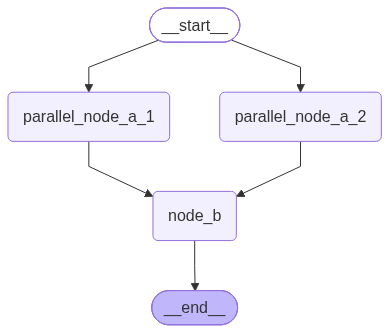

(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fa2-6f6c-bfff-3fb68a3f3bc3'
            }
        },
        'parent_config': None,
        'values': {},
        'metadata': {'source': 'input', 'step': -1, 'parents': {}},
        'next': ['__start__'],
        'tasks': [
            {'id': '113bcb52-aef4-8ee1-be8c-7f336b48a2e4', 'name': '__start__', 'interrupts': (), 'state': None}
        ]
    }
)

(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fa7-6d14-8000-52b7e26c64c3'
            }
        },
        'parent_config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fa2-6f6c-bfff-3fb68a3f3bc3'
            }
        },
        'values': {'initial_state': '初始状态'},
        'metadata': {'source': 'loop', 'step': 0, 'parents': {}},
        'next': ['parallel_node_a_1', 'parallel_node_a_2'],
        'tasks': [
            {
                'id': 'd749671c-0382-3104-27fa-fdc117264c20',
                'name': 'parallel_node_a_1',
                'interrupts': (),
                'state': None
            },
            {
                'id': '66989e94-d29c-df15-c5f7-22e1b5547428',
                'name': 'parallel_node_a_2',
                'interrupts': (),
                'state': None
            }
        ]
    }
)

(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fb0-6464-8001-d642dab9c732'
            }
        },
        'parent_config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fa7-6d14-8000-52b7e26c64c3'
            }
        },
        'values': {
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出'
        },
        'metadata': {'source': 'loop', 'step': 1, 'parents': {}},
        'next': ['node_b'],
        'tasks': [
            {'id': 'eac148af-6c0d-d1a8-2df8-e6c4c32caca0', 'name': 'node_b', 'interrupts': (), 'state': None}
        ]
    }
)

============================== -> 中断前后分界线 <- ==============================


(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fb0-6464-8001-d642dab9c732'
            }
        },
        'parent_config': {
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fa7-6d14-8000-52b7e26c64c3'
            }
        },
        'values': {
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出'
        },
        'metadata': {'source': 'loop', 'step': 1, 'parents': {}},
        'next': ['node_b'],
        'tasks': [
            {
                'id': 'eac148af-6c0d-d1a8-2df8-e6c4c32caca0',
                'name': 'node_b',
                'interrupts': (
                    {'value': 'hello', 'id': 'e37e2b93d01a8ae07840386c4a9b16ff', 'response_schema': None},
                ),
                'state': None
            }
        ]
    }
)

(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fca-6e68-8002-d4655604c9f6'
            }
        },
        'parent_config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '1f1cc619-3fb0-6464-8001-d642dab9c732'
            }
        },
        'values': {
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出',
            'node_b_output': '节点B的输出'
        },
        'metadata': {'source': 'loop', 'step': 2, 'parents': {}},
        'next': [],
        'tasks': []
    }
)

In [12]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from langgraph.types import interrupt, Command

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    interrupt("hello")
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
display(graph)
config = {"configurable": {"thread_id": "123"}}
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["checkpoints"],
    config=config
):
    rprint(chunk)

print('=' * 30, '-> 中断前后分界线 <-', '=' * 30)

for chunk in graph.stream(
    Command(resume=""),
    stream_mode=["checkpoints"],
    config=config
):
    rprint(chunk)

In [13]:
rprint(list(graph.get_state_history(config=config)))

[
    StateSnapshot(
        values={
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出',
            'node_b_output': '节点B的输出'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fca-6e68-8002-d4655604c9f6'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-20T08:38:09.190041+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fb0-6464-8001-d642dab9c732'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出'
        },
        next=('node_b',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fb0-6464-8001-d642dab9c732'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-20T08:38:09.179141+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fa7-6d14-8000-52b7e26c64c3'
            }
        },
        tasks=(
            PregelTask(
                id='eac148af-6c0d-d1a8-2df8-e6c4c32caca0',
                name='node_b',
                path=('__pregel_pull', 'node_b'),
                error=None,
                interrupts=(
                    Interrupt(value='hello', id='e37e2b93d01a8ae07840386c4a9b16ff', response_schema=None),
                ),
                state=None,
                result={'node_b_output': '节点B的输出'}
            ),
        ),
        interrupts=(Interrupt(value='hello', id='e37e2b93d01a8ae07840386c4a9b16ff', response_schema=None),)
    ),
    StateSnapshot(
        values={'initial_state': '初始状态'},
        next=('parallel_node_a_1', 'parallel_node_a_2'),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fa7-6d14-8000-52b7e26c64c3'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-20T08:38:09.175676+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fa2-6f6c-bfff-3fb68a3f3bc3'
            }
        },
        tasks=(
            PregelTask(
                id='d749671c-0382-3104-27fa-fdc117264c20',
                name='parallel_node_a_1',
                path=('__pregel_pull', 'parallel_node_a_1'),
                error=None,
                interrupts=(),
                state=None,
                result={'parallel_node_a_1': '并行节点A-1的输出'}
            ),
            PregelTask(
                id='66989e94-d29c-df15-c5f7-22e1b5547428',
                name='parallel_node_a_2',
                path=('__pregel_pull', 'parallel_node_a_2'),
                error=None,
                interrupts=(),
                state=None,
                result={'parallel_node_a_2': '并行节点A-2的输出'}
            )
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cc619-3fa2-6f6c-bfff-3fb68a3f3bc3'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-20T08:38:09

| 对比维度          | `get_state_history()` | `checkpoints` 流                                 |
| :---------------- | :-------------------- | :----------------------------------------------- |
| 排序方式          | 时间倒序（最新在前）  | 超步编号升序（正向执行顺序）                     |
| 顶层 `interrupts` | 有                    | **无**（中断信息附着在 `tasks[].interrupts` 中） |

**中断时序说明**：检查点 `chunk` 在超步**第一阶段**输出，中断在**第二阶段**触发。因此中断发生时最新检查点仍为上一步（`step=1`），任务中断信息尚为空；恢复执行后第一阶段重新输出 `step=1` 检查点时，中断信息已被记录。

#### 11.2.2.5 `tasks`

**`tasks`** 模式以任务为单位输出开始事件和结果事件。它比 **`updates`** 更偏向运行时观测：除了任务结果，还会暴露任务输入、触发通道、异常和中断信息。

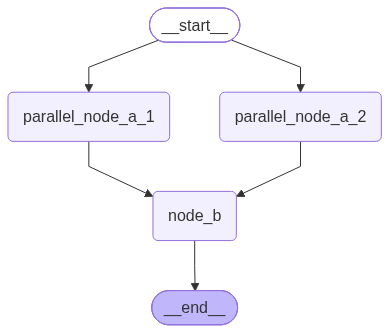

In [14]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()

display(graph)

In [15]:
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["tasks"]
):
    rprint(chunk)

(
    'tasks',
    {
        'id': 'f7190d44-b803-cafc-6ec5-389df1aa04c4',
        'name': 'parallel_node_a_1',
        'input': {'initial_state': '初始状态'},
        'triggers': ('branch:to:parallel_node_a_1',)
    }
)

(
    'tasks',
    {
        'id': '838f11ac-00a8-43e0-cc8b-69f02fdc861d',
        'name': 'parallel_node_a_2',
        'input': {'initial_state': '初始状态'},
        'triggers': ('branch:to:parallel_node_a_2',)
    }
)

(
    'tasks',
    {
        'id': 'f7190d44-b803-cafc-6ec5-389df1aa04c4',
        'name': 'parallel_node_a_1',
        'error': None,
        'result': {'parallel_node_a_1': '并行节点A-1的输出'},
        'interrupts': []
    }
)

(
    'tasks',
    {
        'id': '838f11ac-00a8-43e0-cc8b-69f02fdc861d',
        'name': 'parallel_node_a_2',
        'error': None,
        'result': {'parallel_node_a_2': '并行节点A-2的输出'},
        'interrupts': []
    }
)

(
    'tasks',
    {
        'id': '70e2c56a-23a9-efcd-0857-8c7b6af73285',
        'name': 'node_b',
        'input': {
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出'
        },
        'triggers': ('branch:to:node_b', 'join:parallel_node_a_1+parallel_node_a_2:node_b')
    }
)

(
    'tasks',
    {
        'id': '70e2c56a-23a9-efcd-0857-8c7b6af73285',
        'name': 'node_b',
        'error': None,
        'result': {'node_b_output': '节点B的输出'},
        'interrupts': []
    }
)

**任务 `chunk` 分为两类**：

| 事件类型         | 产生时机                 | 关键字段                                             |
| :--------------- | :----------------------- | :--------------------------------------------------- |
| **任务开始事件** | 任务准备完毕，尚未执行   | `input`（任务输入）、`triggers`（触发通道）          |
| **任务结果事件** | 任务执行完成/失败/中断后 | `error`（异常，`None`=正常）、`result`、`interrupts` |

并行任务时：所有**开始事件**（第一阶段）全部输出后，才出现**结果事件**（第二阶段）。

#### 11.2.2.6 `debug`

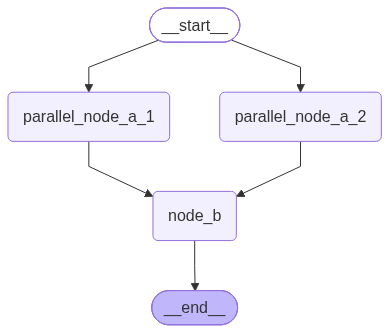

In [18]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    interrupt("hello world!")
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

display(graph)

In [19]:
config = {"configurable": {"thread_id": "123"}}
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["debug"],
    config=config
):
    rprint(chunk)

(
    'debug',
    {
        'step': -1,
        'timestamp': '2026-10-20T09:03:43.232092+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-658e-63e6-bfff-52098ad4bc30'
                }
            },
            'parent_config': None,
            'values': {},
            'metadata': {'source': 'input', 'step': -1, 'parents': {}},
            'next': ['__start__'],
            'tasks': [
                {
                    'id': '4f8f3084-847c-c835-8a50-cd6b24668093',
                    'name': '__start__',
                    'interrupts': (),
                    'state': None
                }
            ]
        }
    }
)

(
    'debug',
    {
        'step': 0,
        'timestamp': '2026-10-20T09:03:43.235630+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-6595-6c7c-8000-8ba0045d12c4'
                }
            },
            'parent_config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-658e-63e6-bfff-52098ad4bc30'
                }
            },
            'values': {'initial_state': '初始状态'},
            'metadata': {'source': 'loop', 'step': 0, 'parents': {}},
            'next': ['parallel_node_a_1', 'parallel_node_a_2'],
            'tasks': [
                {
                    'id': 'ddb9eba4-1329-ce61-4b3a-be1e99a28586',
                    'name': 'parallel_node_a_1',
                    'interrupts': (),
                    'state': None
                },
                {
                    'id': 'b5a12770-64da-f35d-d76d-46330efdcd78',
                    'name': 'parallel_node_a_2',
                    'interrupts': (),
                    'state': None
                }
            ]
        }
    }
)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:03:43.235645+00:00',
        'type': 'task',
        'payload': {
            'id': 'ddb9eba4-1329-ce61-4b3a-be1e99a28586',
            'name': 'parallel_node_a_1',
            'input': {'initial_state': '初始状态'},
            'triggers': ('branch:to:parallel_node_a_1',)
        }
    }
)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:03:43.235649+00:00',
        'type': 'task',
        'payload': {
            'id': 'b5a12770-64da-f35d-d76d-46330efdcd78',
            'name': 'parallel_node_a_2',
            'input': {'initial_state': '初始状态'},
            'triggers': ('branch:to:parallel_node_a_2',)
        }
    }
)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:03:43.243576+00:00',
        'type': 'task_result',
        'payload': {
            'id': 'ddb9eba4-1329-ce61-4b3a-be1e99a28586',
            'name': 'parallel_node_a_1',
            'error': None,
            'result': {'parallel_node_a_1': '并行节点A-1的输出'},
            'interrupts': []
        }
    }
)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:03:43.244884+00:00',
        'type': 'task_result',
        'payload': {
            'id': 'b5a12770-64da-f35d-d76d-46330efdcd78',
            'name': 'parallel_node_a_2',
            'error': None,
            'result': {'parallel_node_a_2': '并行节点A-2的输出'},
            'interrupts': []
        }
    }
)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:03:43.247402+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-65b3-68ee-8001-409e855461dd'
                }
            },
            'parent_config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-6595-6c7c-8000-8ba0045d12c4'
                }
            },
            'values': {
                'initial_state': '初始状态',
                'parallel_node_a_1': '并行节点A-1的输出',
                'parallel_node_a_2': '并行节点A-2的输出'
            },
            'metadata': {'source': 'loop', 'step': 1, 'parents': {}},
            'next': ['node_b'],
            'tasks': [
                {'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9', 'name': 'node_b', 'interrupts': (), 'state': None}
            ]
        }
    }
)

(
    'debug',
    {
        'step': 2,
        'timestamp': '2026-10-20T09:03:43.247416+00:00',
        'type': 'task',
        'payload': {
            'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9',
            'name': 'node_b',
            'input': {
                'initial_state': '初始状态',
                'parallel_node_a_1': '并行节点A-1的输出',
                'parallel_node_a_2': '并行节点A-2的输出'
            },
            'triggers': ('branch:to:node_b', 'join:parallel_node_a_1+parallel_node_a_2:node_b')
        }
    }
)

(
    'debug',
    {
        'step': 2,
        'timestamp': '2026-10-20T09:03:43.251454+00:00',
        'type': 'task_result',
        'payload': {
            'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9',
            'name': 'node_b',
            'error': None,
            'result': {},
            'interrupts': [
                {'value': 'hello world!', 'id': '37b856837947a3722107cf952db97b99', 'response_schema': None}
            ]
        }
    }
)

In [20]:
for chunk in graph.stream(
    Command(resume=""),
    stream_mode=["debug"],
    config=config
):
    rprint(chunk)

(
    'debug',
    {
        'step': 1,
        'timestamp': '2026-10-20T09:04:03.661872+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-65b3-68ee-8001-409e855461dd'
                }
            },
            'parent_config': {
                'configurable': {
                    'thread_id': '123',
                    'checkpoint_ns': '',
                    'checkpoint_id': '1f1cc652-6595-6c7c-8000-8ba0045d12c4'
                }
            },
            'values': {
                'initial_state': '初始状态',
                'parallel_node_a_1': '并行节点A-1的输出',
                'parallel_node_a_2': '并行节点A-2的输出'
            },
            'metadata': {'source': 'loop', 'step': 1, 'parents': {}},
            'next': ['node_b'],
            'tasks': [
                {
                    'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9',
                    'name': 'node_b',
                    'interrupts': (
                        {
                            'value': 'hello world!',
                            'id': '37b856837947a3722107cf952db97b99',
                            'response_schema': None
                        },
                    ),
                    'state': None
                }
            ]
        }
    }
)

(
    'debug',
    {
        'step': 2,
        'timestamp': '2026-10-20T09:04:03.661890+00:00',
        'type': 'task',
        'payload': {
            'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9',
            'name': 'node_b',
            'input': {
                'initial_state': '初始状态',
                'parallel_node_a_1': '并行节点A-1的输出',
                'parallel_node_a_2': '并行节点A-2的输出'
            },
            'triggers': ('branch:to:node_b', 'join:parallel_node_a_1+parallel_node_a_2:node_b')
        }
    }
)

(
    'debug',
    {
        'step': 2,
        'timestamp': '2026-10-20T09:04:03.712779+00:00',
        'type': 'task_result',
        'payload': {
            'id': 'c7957ebd-e647-409c-47bc-ea35b4f4baf9',
            'name': 'node_b',
            'error': None,
            'result': {'node_b_output': '节点B的输出'},
            'interrupts': []
        }
    }
)

(
    'debug',
    {
        'step': 2,
        'timestamp': '2026-10-20T09:04:03.713233+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc653-28e0-6876-8002-feb57c44ce83'
                }
            },
            'parent_config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '1f1cc652-65b3-68ee-8001-409e855461dd'
                }
            },
            'values': {
                'initial_state': '初始状态',
                'parallel_node_a_1': '并行节点A-1的输出',
                'parallel_node_a_2': '并行节点A-2的输出',
                'node_b_output': '节点B的输出'
            },
            'metadata': {'source': 'loop', 'step': 2, 'parents': {}},
            'next': [],
            'tasks': []
        }
    }
)

**`debug` 模式 = `checkpoints` + `tasks` 的统一封装**，外层增加调试字段：

| 字段        | 含义                                  |
| :---------- | :------------------------------------ |
| `step`      | 超步编号                              |
| `timestamp` | chunk 生成时间                        |
| `type`      | `checkpoint` / `task` / `task_result` |
| `payload`   | 对应模式下 chunk 的原始内容           |

**chunk 输出顺序**：每个超步第一阶段按 `准备任务 → 检查点日志 → 任务日志` 的顺序生成，因此任务 chunk 位于前后两个超步的检查点 chunk 之间。中断恢复时对应超步会重新执行，任务 chunk 会再次生成。

   具体来说，**`step=2`** 的超步发生了中断，恢复运行时，**`step=2`** 会重新执行，其第一阶段会再次准备任务，并生成这一阶段的所有任务 **`chunk`**。

#### 11.2.2.7 custom

**`custom`** 模式允许**节点或工具**主动写出自定义数据，调用方通过 **`stream/astream`** 消费这些数据。

它适合输出进度、阶段说明、外部 API 的增量结果等非状态数据。

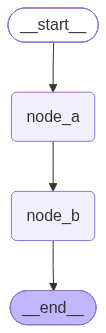

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.runtime import Runtime

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState, runtime: Runtime) -> OverAllState:
    stream_writer = runtime.stream_writer
    stream_writer("节点 A 正在执行...")

    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState, runtime: Runtime) -> OverAllState:
    stream_writer = runtime.stream_writer
    stream_writer("节点 B 正在执行...")

    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
display(graph)

In [3]:
from rich import print as rprint
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["custom"],
):
    rprint(chunk)

('custom', '节点 A 正在执行...')

('custom', '节点 B 正在执行...')

**为什么 `custom` 流中没有节点的返回值？**

节点返回的 `{"node_a_output": "节点A的输出"}` 仍然会合并进图的状态，后续节点可以通过 `state["node_a_output"]` 读取。只订阅 `custom` 时，迭代器仅输出节点通过 `stream_writer(...)` 主动写出的数据，因此看不到节点返回的状态更新。

在上面的 `node_a` 中，两种操作各有作用：

```python
stream_writer("节点 A 正在执行...")        # 向 custom 流写入进度信息。
return {"node_a_output": "节点A的输出"}    # 返回状态更新，交给图合并。
```

`stream_mode` 选择调用方要消费的数据类别，不改变节点实际读写的状态；`stream_writer(...)` 写出的自定义数据也不会自动合并进状态。

| 模式 | 输出内容 |
| :--- | :--- |
| `custom` | `stream_writer(...)` 主动写出的自定义数据。 |
| `updates` | 节点返回的状态更新，通常按节点名组织。 |
| `values` | 合并更新后的状态快照；未限制 `output_keys` 时包含该图的完整流式状态通道。 |

**同时订阅 `custom` 和 `updates`**

下面复用上方已编译的 `graph`，同时观察节点的进度与返回值。每次调用 `graph.stream(...)` 都会执行图；这里是在一次执行中订阅两类输出。


In [ ]:
for mode, data in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["custom", "updates"],
):
    print(mode, data)


上述顺序图的输出为：

```text
custom 节点 A 正在执行...
updates {'node_a': {'node_a_output': '节点A的输出'}}
custom 节点 B 正在执行...
updates {'node_b': {'node_b_output': '节点B的输出'}}
```

其中 `custom` 行来自节点调用的 `stream_writer(...)`，`updates` 行来自节点的 `return {...}`。如果还需要观察每次合并后的状态，可将订阅列表扩展为 `["custom", "updates", "values"]`；最后一个 `values` 快照会包含 `initial_state`、`node_a_output` 和 `node_b_output`。


这里的mode 与 [agent流式输出](/Users/skk/Developer/lang-chain-learn/Chapter07_AGENT/08-Agent的流式输出.ipynb) 完全相同。

### 11.2.3 底层机制


**一句话：`stream()` 一边执行图，一边把执行中产生的数据放进一个内部队列，再把队列里的数据逐个交给调用方。**

**（1）四个角色**

| 角色 | 含义 | 在 `stream()` 中对应 |
| --- | --- | --- |
| 生产者 | 产生流式数据，并把数据**放入**队列的代码 | 运行时内部的几个固定位置，以及节点中的 `stream_writer`、模型回调（见下表） |
| 队列 | 暂存“已经产生、还没交给调用方”的数据，先进先出 | `stream()` 开头创建的 `SyncQueue`；`astream()` 中是 `AsyncQueue` |
| 消费者 | 从队列**取出**数据，包装成 chunk 交出去的代码 | `stream()` 中的 `_output()`，按 `stream_mode`、`version` 决定 chunk 的形状 |
| 调用方 | 使用 chunk 的代码 | 我们写的 `for chunk in graph.stream(...)` |

“生产者 / 消费者”是常见的编程术语：生产指产生数据，消费指取走数据，二者通过队列衔接，不必同时进行。

运行时内部有两个负责执行图的对象，下文会用到：

- **`loop`**（`SyncPregelLoop`）：管理执行进度。每个超步开始时计划要执行哪些节点；超步结束时合并节点写入、保存检查点。
- **`runner`**（`PregelRunner`）：把 `loop` 计划出的节点函数真正执行起来；同一超步有多个节点时并行执行。

各模式的数据由谁、在什么时候放入队列：

| 生产者 | 放入时机 | 放入的模式 |
| --- | --- | --- |
| `loop.tick()` | 超步开始，计划好节点之后 | `checkpoints`、`tasks`（任务开始） |
| 节点执行完成 | 每个节点返回之后 | `updates`、`tasks`（任务结果） |
| `loop.after_tick()` | 本超步所有节点完成、写入合并之后 | `values` |
| `runtime.stream_writer(...)` | 节点运行中，调用时立即放入 | `custom` |
| 模型回调 | 模型每生成一段内容 | `messages` |

没有订阅的模式不会放入队列；`debug` 由 `checkpoints`、`tasks` 改写而来。

**（2）主循环逐行解读**

`Pregel.stream()`（`langgraph/pregel/main.py`）去掉细节后的骨架：

```python
queue = SyncQueue()                                                         # ①
loop = SyncPregelLoop(stream=StreamProtocol(queue.put, stream_mode), ...)   # ②
runner = PregelRunner(...)                                                  # ③
while loop.tick():                                                          # ④
    for _ in runner.tick(loop.tasks):                                       # ⑤
        yield from _output(queue, stream_mode, ...)                         # ⑥
    loop.after_tick()                                                       # ⑦
yield from _output(queue, stream_mode, ...)                                 # ⑧
```

| 行 | 什么时候执行 | 做什么 |
| --- | --- | --- |
| ① | 第一次迭代时 | 创建队列。 |
| ② | 同上 | 创建 `loop`，把放入数据的函数 `queue.put` 和订阅的模式交给它；④⑤⑦ 产生的数据都经它放入队列。`stream_writer` 和模型回调同样调用 `queue.put`。 |
| ③ | 同上 | 创建 `runner`。 |
| ④ | 每个超步开始 | 计划本超步要执行的节点，放入 `checkpoints`、`tasks`。有节点要执行时返回 `True`，进入循环体；没有时返回 `False`，循环结束。 |
| ⑤ | 每个超步执行节点 | `runner.tick()` 执行本超步的节点。它是生成器：执行开始前、每个节点完成后都会暂停一次，`for` 因此转一圈，执行一次 ⑥。节点完成时放入 `updates`。订阅 `custom`、`messages` 时，队列一有新数据它也会暂停。 |
| ⑥ | ⑤ 每次暂停时 | `_output()` 取出队列中的全部数据，包装成 chunk 后逐个 `yield`。`yield` 时 `stream()` 暂停，调用方的 `for` 拿到 chunk；调用方要下一个 chunk 时，`stream()` 才从这里继续执行。 |
| ⑦ | 本超步所有节点完成后 | 合并写入、保存检查点，放入 `values`。这里**只放入、不交出**，要等下一次 ⑥ 或 ⑧ 才交给调用方。 |
| ⑧ | 循环结束后 | 把剩余数据（通常是最后一个 `values`）交给调用方。 |

由此可以理解：

- **惰性执行**：`stream()` 含有 `yield`，是生成器函数。调用 `graph.stream(...)` 只创建生成器，① 还没有执行；`for` 第一次取值时才开始执行。调用方提前 `break`，后续超步也不会执行。
- **为什么 `custom`、`messages` 能实时显示**：它们在节点运行中放入队列，⑤ 随即暂停、⑥ 交出，节点还没结束调用方就能收到。`updates`、`values` 要等节点或超步结束才产生。
- **`invoke` 与 `stream`**：`invoke` 内部就是执行这个循环并消费全部 chunk。默认（`version="v1"`）订阅 `["updates", "values"]`，返回最后一个 `values`，并从 `updates` 中收集 `__interrupt__`。
- **`astream`**：结构相同，换成 `AsyncPregelLoop`、`AsyncQueue` 和 `runner.atick()`，调用方用 `async for` 消费。

**（3）对照一次真实运行**

下面的代码给 ④⑤⑦ 和 `queue.put` 装上“监视器”：只打印主循环走到哪一步、队列放入了什么，不改变行为，结束后恢复原函数。图为 `START → node_a → node_b → END`，`node_a` 先调用 `stream_writer`，`sleep(0.5)` 后才返回。

In [ ]:
import time
from typing import TypedDict

from langgraph._internal._queue import SyncQueue
from langgraph.graph import END, START, StateGraph
from langgraph.pregel._loop import SyncPregelLoop
from langgraph.pregel._runner import PregelRunner
from langgraph.runtime import Runtime

# ---------- 监视器：只打印主循环走到哪一步、队列放入了什么，不改变行为 ----------
orig_put, orig_tick = SyncQueue.put, SyncPregelLoop.tick
orig_after_tick, orig_runner_tick = SyncPregelLoop.after_tick, PregelRunner.tick


def spy_put(self, item, *args, **kwargs):  # 所有生产者最终都调用 queue.put
    _, mode, payload = item
    print(f"        放入队列：{mode} {payload}")
    return orig_put(self, item, *args, **kwargs)


def spy_tick(self):  # ④
    step = self.step
    has_tasks = orig_tick(self)
    print(f"④ loop.tick()        超步 {step}：计划出 {[t.name for t in self.tasks.values()]}")
    return has_tasks


def spy_runner_tick(self, tasks, **kwargs):  # ⑤
    tasks = list(tasks)
    print(f"⑤ runner.tick()      执行 {[t.name for t in tasks]}")
    yield from orig_runner_tick(self, tasks, **kwargs)


def spy_after_tick(self):  # ⑦
    print("⑦ loop.after_tick()  合并写入、保存检查点")
    return orig_after_tick(self)


# ---------- 图：START → node_a → node_b → END ----------
class TraceState(TypedDict):
    query: str
    node_a_output: str
    node_b_output: str


def trace_node_a(state: TraceState, runtime: Runtime) -> TraceState:
    print("        [node_a 运行中] 调用 stream_writer")
    runtime.stream_writer("节点 A 正在执行...")
    time.sleep(0.5)  # 节点还没有结束
    print("        [node_a 运行中] 即将返回")
    return {"node_a_output": "A"}


def trace_node_b(state: TraceState) -> TraceState:
    return {"node_b_output": "B"}


trace_builder = StateGraph(TraceState)
trace_builder.add_node("node_a", trace_node_a)
trace_builder.add_node("node_b", trace_node_b)
trace_builder.add_edge(START, "node_a")
trace_builder.add_edge("node_a", "node_b")
trace_builder.add_edge("node_b", END)
trace_graph = trace_builder.compile()

SyncQueue.put, SyncPregelLoop.tick = spy_put, spy_tick
SyncPregelLoop.after_tick, PregelRunner.tick = spy_after_tick, spy_runner_tick
try:
    chunks = trace_graph.stream({"query": "你好"}, stream_mode=["updates", "values", "custom"])
    print("已创建迭代器，主循环还没有开始")
    for mode, data in chunks:  # ⑥ / ⑧ 每 yield 一次，这里就收到一个 chunk
        print(f"                    【调用方收到】{mode} {data}")
finally:  # 恢复原函数
    SyncQueue.put, SyncPregelLoop.tick = orig_put, orig_tick
    SyncPregelLoop.after_tick, PregelRunner.tick = orig_after_tick, orig_runner_tick

运行结果：

```text
已创建迭代器，主循环还没有开始
④ loop.tick()        超步 0：计划出 ['__start__']
⑤ runner.tick()      执行 ['__start__']
⑦ loop.after_tick()  合并写入、保存检查点
        放入队列：values {'query': '你好'}
④ loop.tick()        超步 1：计划出 ['node_a']
⑤ runner.tick()      执行 ['node_a']
                    【调用方收到】values {'query': '你好'}
        [node_a 运行中] 调用 stream_writer
        放入队列：custom 节点 A 正在执行...
                    【调用方收到】custom 节点 A 正在执行...
        [node_a 运行中] 即将返回
        放入队列：updates {'node_a': {'node_a_output': 'A'}}
                    【调用方收到】updates {'node_a': {'node_a_output': 'A'}}
⑦ loop.after_tick()  合并写入、保存检查点
        放入队列：values {'query': '你好', 'node_a_output': 'A'}
④ loop.tick()        超步 2：计划出 ['node_b']
⑤ runner.tick()      执行 ['node_b']
                    【调用方收到】values {'query': '你好', 'node_a_output': 'A'}
        放入队列：updates {'node_b': {'node_b_output': 'B'}}
                    【调用方收到】updates {'node_b': {'node_b_output': 'B'}}
⑦ loop.after_tick()  合并写入、保存检查点
        放入队列：values {'query': '你好', 'node_a_output': 'A', 'node_b_output': 'B'}
④ loop.tick()        超步 3：计划出 []
                    【调用方收到】values {'query': '你好', 'node_a_output': 'A', 'node_b_output': 'B'}
```

对照主循环：

- “已创建迭代器”先于 ④ 打印：调用 `graph.stream(...)` 时主循环还没开始。
- 超步 0 执行内置任务 `__start__`，把输入写进状态；⑦ 放入第一个 `values`，但它要到超步 1 的 ⑤ 开始执行、第一次暂停时才由 ⑥ 交出。之后的 `values` 都是这样：**上一个超步结束时放入，下一个超步开始执行时交出**。
- `custom` 在“即将返回”之前就被调用方收到：节点还在运行，数据已经交出。
- 节点返回后放入的 `updates` 随即交出。超步 3 计划不出节点，④ 返回 `False`，循环结束，最后一个 `values` 由 ⑧ 交出。

监视器替换的是 LangGraph 内部对象的方法，仅用于学习观察，业务代码中不要这样做。以上结果在 `langgraph 1.2.16` 环境核对。

## 11.3 astream_events

**`astream_events`** 用于异步获取图运行过程中产生的 **`Runnable` 标准事件**：哪个组件开始了、产出了什么、何时结束、被谁调用。`stream/astream` 关心“图的状态怎么变”，`astream_events` 关心“哪些组件在运行”。

要看懂这些事件，先要知道 **`Runnable`** 是什么。

### 11.3.1 什么是 Runnable

**`Runnable`** 是 `langchain_core` 定义的抽象基类，表示“一个可调用的工作单元”。子类只需实现 `invoke`，其余方法都有默认实现：

```python
# langchain_core/runnables/base.py:134（简化）
class Runnable(ABC, Generic[Input, Output]):
    @abstractmethod
    def invoke(self, input, config=None, **kwargs): ...  # 子类必须实现

    async def ainvoke(...)          # 默认：把 invoke 放进线程池执行
    def batch(...)                  # 默认：用线程池并发调用 invoke
    def stream(...)                 # 默认：yield self.invoke(...)，整个结果作为一块
    def astream_events(...)         # 默认：基于回调生成事件（见 11.3.4）
    def __or__(self, other)         # a | b → RunnableSequence
```

| 方法 | 作用 |
| :--- | :--- |
| `invoke` / `ainvoke` | 一个输入 → 一个输出 |
| `batch` / `abatch` | 多个输入 → 多个输出 |
| `stream` / `astream` | 边执行边产出**输出** |
| `astream_events` | 边执行边产出**运行事件** |
| `\|` 运算符 | 把多个 `Runnable` 串成 `RunnableSequence` |

模型、提示词、工具、节点、编译图都实现了这套接口，所以调用方式统一，运行过程也能被同一套事件机制记录。

### 11.3.2 Runnable 组件

下面的图有两个节点：`chat` 调用 `prompt | model`，`count` 调用工具 `count_chars`。先检查各组件是否为 `Runnable`，后面的小节都复用这个 `event_graph`。

所有 Runnable 对象都提供了额外的方法，可以用来修改它们的行为（例如，添加重试策略、添加生命周期监听器、使其可配置等）。这些方法适用于任何 Runnable ，包括通过组合其他 Runnable 构成的 Runnable chain。详情请参阅各个方法的说明。

模型使用 `GenericFakeChatModel`：不调用 API，把预设回复按空格切开后流式输出。

In [ ]:
from itertools import cycle
from typing import TypedDict

from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import Runnable, RunnableLambda
from langchain_core.tools import tool
from langgraph.graph import END, START, StateGraph


class EventState(TypedDict):
    question: str
    answer: str
    length: int


prompt = ChatPromptTemplate.from_messages([("human", "{q}")])
model = GenericFakeChatModel(messages=cycle([AIMessage("你好 世界")]))
chain = prompt | model


@tool
def count_chars(text: str) -> int:
    """统计字符数"""
    return len(text)


def chat(state: EventState) -> dict:
    # 用 .text 而不是 .content：v3 下 content 会变成内容块列表（见 11.3.4）
    return {"answer": chain.invoke({"q": state["question"]}).text}


def count(state: EventState) -> dict:
    return {"length": count_chars.invoke({"text": state["answer"]})}


builder = StateGraph(EventState)
builder.add_node("chat", chat)
builder.add_node("count", count)
builder.add_edge(START, "chat")
builder.add_edge("chat", "count")
builder.add_edge("count", END)
event_graph = builder.compile()

# key: "编译图 event_graph" value: event_graph
for label, obj in {
    "编译图 event_graph": event_graph,
    "节点 chat": event_graph.nodes["chat"].bound,
    "提示词 prompt": prompt,
    "模型 model": model,
    "工具 count_chars": count_chars,
    "函数 RunnableLambda(len)": RunnableLambda(len),
    "组合 prompt | model": chain,
}.items():
    print(f"{type(obj).__name__:<22} {isinstance(obj, Runnable)!s:<6} {label}")

print([c.__name__ for c in type(event_graph).__mro__[:4]])

# 统一的调用方式
print(prompt.invoke({"q": "hi"}))
print(count_chars.invoke({"text": "abc"}))
print(event_graph.invoke({"question": "hi"}))

CompiledStateGraph     True   编译图 event_graph
RunnableCallable       True   节点 chat
ChatPromptTemplate     True   提示词 prompt
GenericFakeChatModel   True   模型 model
StructuredTool         True   工具 count_chars
RunnableLambda         True   函数 RunnableLambda(len)
RunnableSequence       True   组合 prompt | model
['CompiledStateGraph', 'Pregel', 'PregelProtocol', 'Runnable']
messages=[HumanMessage(content='hi', additional_kwargs={}, response_metadata={})]
3
{'question': 'hi', 'answer': '你好 世界', 'length': 5}


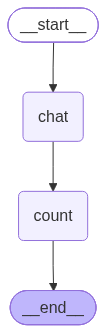

In [6]:
display(event_graph)

- 7 个组件都是 `Runnable`，所以都能直接 `.invoke(...)`。
- 编译图的继承链：`CompiledStateGraph → Pregel → PregelProtocol → Runnable`。
- 节点 `chat` 原本是普通函数，`add_node` 时被包装成 `RunnableCallable`：

```python
# langgraph/_internal/_runnable.py:550（简化）
def coerce_to_runnable(thing, *, name, trace):
    if isinstance(thing, Runnable):
        return thing                          # 已是 Runnable，原样使用
    elif callable(thing):
        return RunnableCallable(thing, ...)   # 普通函数 → RunnableCallable
```

因此一次图运行就是一棵 **`Runnable` 调用树**：`LangGraph`（编译图）→ 节点 → 节点内调用的 `RunnableSequence`、模型、工具。

### 11.3.3 Runnable 事件

事件名遵循 `on_<类型>_<阶段>`：

| 类型 | 对应组件 |
| :--- | :--- |
| `chain` | 编译图、节点、`RunnableSequence`、`RunnableLambda` 等通用 `Runnable` |
| `prompt` | 提示词模板 |
| `chat_model` / `llm` | 聊天模型 / 文本补全模型 |
| `tool` | 工具（只有 `start`、`end`） |
| `retriever` | 检索器 |

| 阶段 | `data` 中的内容 |
| :--- | :--- |
| `start` | `input`：组件输入 |
| `stream` | `chunk`：中间产出 |
| `end` | `output`：最终输出（通常也带 `input`） |

**事件从哪来**：每个 `Runnable` 运行时都会触发回调（`on_chain_start`、`on_chat_model_start`……）。`astream_events` 注册一个回调处理器，把每次回调转成一个事件字典：

```python
# langchain_core/tracers/event_stream.py:548（简化）
async def on_chain_start(self, serialized, inputs, *, run_id, run_type=None, name=None, ...):
    run_type_ = run_type or "chain"              # 没传类型就是 chain；提示词会传 "prompt"
    self._send({
        "event": f"on_{run_type_}_start",        # 拼出事件名
        "data": {"input": inputs},
        "name": name_,
        "run_id": str(run_id),
        "parent_ids": self._get_parent_ids(run_id),  # 沿 parent_run_id 向上走到根，再反转
        ...
    }, run_type_)
```

### 11.3.4 astream_events的版本

从 **`LangGraph 1.2.0`** 开始，**`astream_events`** 支持三个版本：

| 版本             | 基础                                       | 特点                                                 | 入口                                                         |
| :--------------- | :----------------------------------------- | :--------------------------------------------------- | :----------------------------------------------------------- |
| **`v1`**         | `Runnable` 标准事件                        | `parent_ids` 始终为空列表                            | `astream_events(version="v1")`                               |
| **`v2`**（默认） | `Runnable` 标准事件                        | `parent_ids` 可表达完整父级运行链，改进父子调用关系  | `astream_events(version="v2")`                               |
| **`v3`**         | `Pregel` 原始流（= `stream/astream` 底层） | 全新协议，通过类型化投影消费（见下表），独立于 v1/v2 | `astream_events(version="v3")` / `stream_events(version="v3")` |


### 11.3.5 astream_events的示例


In [7]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
async for chunk in graph.astream_events(
    {"initial_state": "初始状态"},
    version="v2"
):
    rprint(chunk)

{
    'event': 'on_chain_start',
    'data': {'input': {'initial_state': '初始状态'}},
    'name': 'LangGraph',
    'tags': [],
    'run_id': '01a15987-8a55-77d1-8f30-b35c2e1ace15',
    'metadata': {'ls_integration': 'langgraph'},
    'parent_ids': []
}

{
    'event': 'on_chain_start',
    'data': {'input': {'initial_state': '初始状态'}},
    'name': 'node_a',
    'tags': ['graph:step:1'],
    'run_id': '01a15987-8a59-75ef-a051-a406ecd39350',
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 1,
        'langgraph_node': 'node_a',
        'langgraph_triggers': ('branch:to:node_a',),
        'langgraph_path': ('__pregel_pull', 'node_a'),
        'langgraph_checkpoint_ns': 'node_a:9faa70ee-11ba-6baf-e8f9-3dd70a901b08'
    },
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_stream',
    'run_id': '01a15987-8a59-75ef-a051-a406ecd39350',
    'name': 'node_a',
    'tags': ['graph:step:1'],
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 1,
        'langgraph_node': 'node_a',
        'langgraph_triggers': ('branch:to:node_a',),
        'langgraph_path': ('__pregel_pull', 'node_a'),
        'langgraph_checkpoint_ns': 'node_a:9faa70ee-11ba-6baf-e8f9-3dd70a901b08'
    },
    'data': {'chunk': {'node_a_output': '节点A的输出'}},
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_end',
    'data': {'output': {'node_a_output': '节点A的输出'}, 'input': {'initial_state': '初始状态'}},
    'run_id': '01a15987-8a59-75ef-a051-a406ecd39350',
    'name': 'node_a',
    'tags': ['graph:step:1'],
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 1,
        'langgraph_node': 'node_a',
        'langgraph_triggers': ('branch:to:node_a',),
        'langgraph_path': ('__pregel_pull', 'node_a'),
        'langgraph_checkpoint_ns': 'node_a:9faa70ee-11ba-6baf-e8f9-3dd70a901b08',
        'LANGSMITH_PROJECT': 'pr-clear-harmony-32',
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com'
    },
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_stream',
    'run_id': '01a15987-8a55-77d1-8f30-b35c2e1ace15',
    'name': 'LangGraph',
    'tags': [],
    'metadata': {'ls_integration': 'langgraph'},
    'data': {'chunk': {'node_a': {'node_a_output': '节点A的输出'}}},
    'parent_ids': []
}

{
    'event': 'on_chain_start',
    'data': {'input': {'initial_state': '初始状态', 'node_a_output': '节点A的输出'}},
    'name': 'node_b',
    'tags': ['graph:step:2'],
    'run_id': '01a15987-8a5f-772d-8e6b-beec645ee15b',
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 2,
        'langgraph_node': 'node_b',
        'langgraph_triggers': ('branch:to:node_b',),
        'langgraph_path': ('__pregel_pull', 'node_b'),
        'langgraph_checkpoint_ns': 'node_b:d2eab6ae-7675-78e2-4178-12f1adba3ea6'
    },
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_stream',
    'run_id': '01a15987-8a5f-772d-8e6b-beec645ee15b',
    'name': 'node_b',
    'tags': ['graph:step:2'],
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 2,
        'langgraph_node': 'node_b',
        'langgraph_triggers': ('branch:to:node_b',),
        'langgraph_path': ('__pregel_pull', 'node_b'),
        'langgraph_checkpoint_ns': 'node_b:d2eab6ae-7675-78e2-4178-12f1adba3ea6'
    },
    'data': {'chunk': {'node_b_output': '节点B的输出'}},
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_end',
    'data': {
        'output': {'node_b_output': '节点B的输出'},
        'input': {'initial_state': '初始状态', 'node_a_output': '节点A的输出'}
    },
    'run_id': '01a15987-8a5f-772d-8e6b-beec645ee15b',
    'name': 'node_b',
    'tags': ['graph:step:2'],
    'metadata': {
        'ls_integration': 'langgraph',
        'langgraph_step': 2,
        'langgraph_node': 'node_b',
        'langgraph_triggers': ('branch:to:node_b',),
        'langgraph_path': ('__pregel_pull', 'node_b'),
        'langgraph_checkpoint_ns': 'node_b:d2eab6ae-7675-78e2-4178-12f1adba3ea6',
        'LANGSMITH_PROJECT': 'pr-clear-harmony-32',
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com'
    },
    'parent_ids': ['01a15987-8a55-77d1-8f30-b35c2e1ace15']
}

{
    'event': 'on_chain_stream',
    'run_id': '01a15987-8a55-77d1-8f30-b35c2e1ace15',
    'name': 'LangGraph',
    'tags': [],
    'metadata': {
        'ls_integration': 'langgraph',
        'LANGSMITH_PROJECT': 'pr-clear-harmony-32',
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com'
    },
    'data': {'chunk': {'node_b': {'node_b_output': '节点B的输出'}}},
    'parent_ids': []
}

{
    'event': 'on_chain_end',
    'data': {
        'output': {'initial_state': '初始状态', 'node_a_output': '节点A的输出', 'node_b_output': '节点B的输出'}
    },
    'run_id': '01a15987-8a55-77d1-8f30-b35c2e1ace15',
    'name': 'LangGraph',
    'tags': [],
    'metadata': {
        'ls_integration': 'langgraph',
        'LANGSMITH_PROJECT': 'pr-clear-harmony-32',
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com'
    },
    'parent_ids': []
}

# 问题
### 1. agent 的 stream/astream 与 graph 的 stream/astream 的异同

这里的 `graph` 指通过 `StateGraph(...).compile()` 得到的编译图，`agent` 指通过 `langchain.agents.create_agent()` 创建的 Agent。以下结论按本项目的 **LangChain 1.4.6 / LangGraph 1.2.16** 核对。

**核心关系：`create_agent()` 返回的也是 `CompiledStateGraph`，两者使用同一套 `stream` / `astream` 实现。** `create_agent()` 负责构建模型、工具、中间件等节点及其连接，再编译为可执行图；手动构建 Graph 时，这些结构由我们定义。

**（1）相同点：流式接口与消费规则一致**

| 对比维度 | 共同规则 |
| :--- | :--- |
| 方法实现 | `CompiledStateGraph` 继承 `Pregel` 的 `stream` / `astream`；`create_agent()` 创建的 Agent 使用同样的方法。 |
| 同步与异步 | `stream()` 返回同步迭代器，通过 `for` 消费；`astream()` 返回异步迭代器，通过 `async for` 消费。 |
| 参数 | 都支持 `input`、`config`、`context`、`stream_mode`、`print_mode`、`output_keys`、`interrupt_before`、`interrupt_after`、`durability`、`control`、`subgraphs`、`debug`、`version` 等参数。具体输入、字段名和节点名需符合各自图的定义。 |
| 流模式 | 本章介绍的 `values`、`updates`、`messages`、`custom`、`checkpoints`、`tasks`、`debug` 均属于同一套运行时能力，Agent 也可以使用。Agent 教程通常重点展示 `updates`、`messages`、`custom`。 |
| 输出封装 | `v1` 下的单模式、模式列表及子图封装规则相同；`v2` 都使用包含 `type`、`ns`、`data` 等字段的统一格式，具体见 11.2.1。 |
| 中断与持久化 | 均使用 LangGraph 的中断、检查点与恢复机制。需要持久化或跨调用恢复时，都应配置 checkpointer 和相应的线程配置；创建 Agent 本身不会自动提供本地持久化。 |
| 自定义进度 | 节点或工具都可以通过 `StreamWriter` 主动写出进度，再由 `custom` 模式消费。 |

在已有 `graph` 和 `agent` 实例时，可以直接核对方法来源：

```python
# 在本项目当前版本中均为 True。
type(graph) is type(agent)
graph.stream.__func__ is agent.stream.__func__
graph.astream.__func__ is agent.astream.__func__
```

**（2）差异：图的结构与配置决定实际输出内容**

| 对比维度 | 手动构建的 Graph | `create_agent()` 创建的 Agent |
| :--- | :--- | :--- |
| 状态结构 | 自行定义业务字段，例如 `initial_state`、`node_a_output`；也可以使用消息状态。 | 以 `messages` 为核心，可通过自定义状态和中间件扩展；配置结构化输出后还可能包含 `structured_response`。 |
| 节点结构 | 节点名及节点逻辑由开发者定义，例如本章的 `node_a`、`llm_node`。 | 构建器生成 `model`、`tools`（启用客户端工具执行时）及中间件等节点，具体结构取决于创建配置。 |
| 执行流程 | 可以是顺序、分支、并行或循环，取决于边和路由定义。 | 通常执行模型与工具之间的循环，直到模型完成回答或其他结束条件生效；中间件可进一步影响流程。 |
| `values` 内容 | 输出所选业务状态通道的快照。 | 输出所选 Agent 状态通道的快照，通常可观察累积的消息历史。 |
| `updates` 内容 | 外层节点名和内层字段来自自定义节点更新。 | 常见为 `model` 的 AI 消息更新、`tools` 的工具结果更新，以及中间件产生的更新。 |
| `messages` 来源 | 来自图中实际发生的模型调用；本章案例只在 `llm_node` 中调用一次模型。 | 一次 Agent 执行可能多次调用模型，流中可能同时包含工具调用片段和各轮回答片段。 |
| 已绑定配置 | 取决于编译、`with_config()` 及调用时传入的设置。 | 工厂可能附带递归上限、追踪元数据等配置；相同的方法实现不代表两个实例的所有配置值都相同。 |

上述差异取决于构建方式。我们也可以手动构建与 Agent 相同的模型—工具循环，并得到相同语义的流式输出。

例如，同样使用 `stream_mode="updates"`，本章消息案例中的图会产生类似更新：

```python
{"llm_node": {"messages": [AIMessage(content="你好！")]}}
```

一个调用工具一次的 Agent 则可能依次产生以下更新（省略部分消息字段，仅示意输出结构）：

```python
# 第一轮模型调用：提出工具调用请求。
{"model": {"messages": [AIMessage(content="", tool_calls=[...])]}}

# 工具执行完成：将工具结果写入消息状态。
{"tools": {"messages": [ToolMessage(content="查询结果", ...)]}}

# 第二轮模型调用：根据工具结果生成回答。
{"model": {"messages": [AIMessage(content="根据查询结果……")]}}
```

这些输出遵循同一条 `updates` 规则：按节点输出状态更新。示例中的模型、工具、模型顺序来自 Agent 的执行流程；具体轮次和事件数量随实际调用变化。

**（3）消费 Agent 的 `messages` 流时，应区分模型调用轮次**

`messages` 在两者中都表示模型消息片段及调用元数据。Agent 的一次执行可能包含多轮模型调用，因此消费时需要关注：

- `metadata["langgraph_node"]` 可用于区分节点；同一个 `model` 节点可能执行多轮，仅按节点名筛选仍可能得到多条不同消息。
- 应结合消息 `id`、执行超步及内容类型区分不同调用，避免把所有片段直接拼接成一条“最终回答”。
- 模型提出工具调用时，片段可能包含 `tool_call_chunks`，而 `content` 为空；这仍然是模型输出的一部分。
- 普通工具函数的执行结果通常通过 `updates` 中的 `ToolMessage` 观察；工具执行过程中的主动进度通知可通过 `custom` 观察。最终回答应结合执行结果与结束条件识别。
- 将 Agent 嵌入外层 Graph 后，它成为子图。需要观察其内部流式事件时，应在外层调用中启用 `subgraphs=True`，并结合命名空间判断来源。

同样的注意事项也适用于包含多次模型调用、工具执行或子图的手动 Graph。

这里讨论的是 `create_agent()` 返回的编译图。旧版 `AgentExecutor` 或其他框架中同名的 `stream()` / `astream()`，需要分别核对接口与输出协议。

参考：[`create_agent` 官方 API](https://reference.langchain.com/python/langchain/agents/factory/create_agent)、[LangChain Agent 流式输出指南](https://docs.langchain.com/oss/python/langchain/streaming)、[LangGraph 流式输出指南](https://docs.langchain.com/oss/python/langgraph/streaming)。


### 2. astream_events 输出理解

**一句话：`astream_events` 把一次运行拆成一串字典，每个字典记录“某个 `Runnable` 在某个时刻的情况”。**

下面从最简单的例子开始，分三步看；最后再用源码解释为什么是这样。

**第 1 步：一个最简单的 `Runnable`**

先对同一个 `Runnable` 分别调用 `invoke`、`astream`、`astream_events`，比较三者交出来的东西。`show` 把一个事件打印成一行，缩进的层数等于 `parent_ids` 的长度（`parent_ids` 的含义见第 2 步）。

In [1]:
from langchain_core.runnables import RunnableLambda


def show(e):
    """一行打印一个事件：缩进 = parent_ids 的长度"""
    indent = "  " * len(e["parent_ids"])
    print(f"{indent}{e['event']:<16} name={e['name']:<10} data={e['data']}")


add_one = RunnableLambda(lambda x: x + 1, name="add_one")

print("invoke   →", add_one.invoke(1))
print("astream  →", [c async for c in add_one.astream(1)])
print("astream_events ↓")
async for e in add_one.astream_events(1):
    show(e)

invoke   → 2
astream  → [2]
astream_events ↓
on_chain_start   name=add_one    data={'input': 1}
on_chain_stream  name=add_one    data={'chunk': 2}
on_chain_end     name=add_one    data={'output': 2}


同一次运行，三种方法交出来的东西不同：

| 方法 | 交出什么 |
| :--- | :--- |
| `invoke` | 只有最终结果 `2` |
| `astream` | 产出的块 `[2]`；这个函数不分块，整个结果作为一块 |
| `astream_events` | 这次运行的 **3 个时刻**：开始（`input` 为 `1`）→ 产出一块（`chunk` 为 `2`）→ 结束（`output` 为 `2`） |

`astream_events` 交出的每一项都是一个字典，`show` 只打印了其中的 `event`、`name`、`data`、`parent_ids`，完整字段见 11.3.3。

**第 2 步：两节点的图，和 `astream` 对照**

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class S(TypedDict):
    x: int


def node_a(state: S) -> dict:
    return {"x": state["x"] + 1}


def node_b(state: S) -> dict:
    return {"x": state["x"] * 2}


g = StateGraph(S)
g.add_node("node_a", node_a)
g.add_node("node_b", node_b)
g.add_edge(START, "node_a")
g.add_edge("node_a", "node_b")
g.add_edge("node_b", END)
graph = g.compile()

print("astream ↓")
async for c in graph.astream({"x": 1}):
    print("  ", c)
print("astream_events ↓")
events = [e async for e in graph.astream_events({"x": 1})]
for e in events:
    show(e)

root_chunks = [e["data"]["chunk"] for e in events
               if e["event"] == "on_chain_stream" and e["parent_ids"] == []]
print("graph.stream_mode =", graph.stream_mode)
print("根的 stream chunk == astream 输出：", root_chunks == [c async for c in graph.astream({"x": 1})])

astream ↓
   {'node_a': {'x': 2}}
   {'node_b': {'x': 4}}
astream_events ↓
on_chain_start   name=LangGraph  data={'input': {'x': 1}}
  on_chain_start   name=node_a     data={'input': {'x': 1}}
  on_chain_stream  name=node_a     data={'chunk': {'x': 2}}
  on_chain_end     name=node_a     data={'output': {'x': 2}, 'input': {'x': 1}}
on_chain_stream  name=LangGraph  data={'chunk': {'node_a': {'x': 2}}}
  on_chain_start   name=node_b     data={'input': {'x': 2}}
  on_chain_stream  name=node_b     data={'chunk': {'x': 4}}
  on_chain_end     name=node_b     data={'output': {'x': 4}, 'input': {'x': 2}}
on_chain_stream  name=LangGraph  data={'chunk': {'node_b': {'x': 4}}}
on_chain_end     name=LangGraph  data={'output': {'x': 4}}
graph.stream_mode = updates
根的 stream chunk == astream 输出： True


先说明两个字段：

- **`run_id`**：一个组件每被调用一次，就分配一个唯一 ID。
- **`parent_ids`**：调用当前组件的那些组件的 `run_id`，顺序是“根 → 直接父级”。图本身没有父级，所以是空列表。

按缩进分两层看：

- **顶格（`parent_ids` 为空）**：图本身，名字是 `LangGraph`。它有开始、两次产出、结束 4 个事件。两次产出的 `chunk` **与 `astream` 的 2 条输出完全相同**（最后一行为 `True`）。编译图的 `astream` 默认使用 `updates` 模式，所以 `chunk` 的格式是 `{节点名: 更新}`。
- **缩进一格**：节点 `node_a`、`node_b`，父级是图。每个节点有开始、产出、结束 3 个事件：`input` 是节点收到的状态，`chunk` / `output` 是节点 `return` 的更新；节点只 `return` 一次，所以只有一个 `chunk`。
- **事件顺序就是执行顺序**：`node_a` 跑完 → 图交出 `node_a` 的更新 → 再轮到 `node_b`。

所以：**`astream_events` 的输出 = `astream` 的输出（变成图的 `on_chain_stream`）+ 图内每个 `Runnable` 的开始、产出、结束。**

**第 3 步：节点里调用模型**

`GenericFakeChatModel` 是 `langchain_core` 自带的假模型：不调用 API，把预设回复按空格切开后逐块输出。

In [3]:
from itertools import cycle
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage

model = GenericFakeChatModel(messages=cycle([AIMessage("你好 世界")]))


class ChatState(TypedDict):
    answer: str


def chat(state: ChatState) -> dict:
    return {"answer": model.invoke("hi").text}


g2 = StateGraph(ChatState)
g2.add_node("chat", chat)
g2.add_edge(START, "chat")
g2.add_edge("chat", END)
chat_graph = g2.compile()

async for e in chat_graph.astream_events({}):
    if e["event"] == "on_chat_model_stream":
        e = {**e, "data": {"chunk": e["data"]["chunk"].content}}  # 只看 chunk 的文字
    elif e["name"] == "GenericFakeChatModel":
        e = {**e, "data": "..."}  # 省略模型的长输入输出
    show(e)

on_chain_start   name=LangGraph  data={'input': {}}
  on_chain_start   name=chat       data={'input': {}}
    on_chat_model_start name=GenericFakeChatModel data=...
    on_chat_model_stream name=GenericFakeChatModel data={'chunk': '你好'}
    on_chat_model_stream name=GenericFakeChatModel data={'chunk': ' '}
    on_chat_model_stream name=GenericFakeChatModel data={'chunk': '世界'}
    on_chat_model_end name=GenericFakeChatModel data=...
  on_chain_stream  name=chat       data={'chunk': {'answer': '你好 世界'}}
  on_chain_end     name=chat       data={'output': {'answer': '你好 世界'}, 'input': {}}
on_chain_stream  name=LangGraph  data={'chunk': {'chat': {'answer': '你好 世界'}}}
on_chain_end     name=LangGraph  data={'output': {'answer': '你好 世界'}}


- 模型在 `chat` 节点里被调用，所以它的事件缩进两格：父级依次是图、`chat` 节点。
- 模型的类型是 `chat_model`，所以事件名是 `on_chat_model_*`；逐个 token（`'你好'`、`' '`、`'世界'`）出现在 `on_chat_model_stream` 里。
- 默认的 `astream` 只交出 `{'chat': {'answer': '你好 世界'}}`，看不到节点内部。**`astream_events` 多出来的，就是“节点里发生了什么”。** 只要 token 时，筛出 `on_chat_model_stream` 即可。
- 节点里写的是 `model.invoke(...)`（不是流式调用），却仍有 3 个 token 事件，原因见下面源码的第 ④ 段。
- 代码中两行 `e = {**e, ...}` 只是为了让打印更短，不影响事件本身。

**为什么是这样：源码**

先定义一个词：**回调（callback）**。`Runnable` 在开始、产出、结束时，会主动调用一组约定好的函数，如 `on_chain_start`、`on_chain_end`、`on_chat_model_start`。谁被放进 `config["callbacks"]`，谁就会被调用；`config` 会一路传给内层的节点和模型，所以内层组件运行时也会触发同一批回调。

以下源码都在 `langchain_core/tracers/event_stream.py`，均为简化版。

**① 入口：后台跑 `astream`，前台取事件**（1004–1080 行）

```python
event_streamer = _AstreamEventsCallbackHandler(...)                 # 1
config["callbacks"] = [event_streamer]                              # 2

async def consume_astream():
    stream = runnable.astream(value, config)                        # 3
    async for _ in event_streamer.tap_output_aiter(run_id, stream): # 4
        pass                                                        # 5
task = asyncio.create_task(consume_astream())                       # 6

async for event in event_streamer:                                  # 7
    yield event
```

1. 创建一个回调处理器，下文称“收集器”，所有事件都会先放进它。
2. 把收集器放进 `config` 的回调列表。图、节点、模型运行时触发的回调都会通知它。
3. 照常调用 `astream`，图的执行方式与 11.2 完全相同。
4. `tap_output_aiter` 把 `astream` 的每个输出块“截一下”：先生成一个 stream 事件，再把块原样放行（见 ②）。
5. 放行的块直接丢弃：`astream_events` 不会把 `astream` 的输出原样交给调用方。
6. 第 3–5 行放进后台任务运行。
7. 前台从收集器里逐个取出事件，交给调用方的 `async for`。

**② 图的 `on_chain_stream`：截获 `astream` 的输出**（178–225 行，`tap_output_aiter`）

```python
event = {"event": f"on_{run_type}_stream", "name": name, "run_id": ..., "parent_ids": ...}  # 1
async for chunk in output:                                  # 2
    self._send({**event, "data": {"chunk": chunk}})         # 3
    yield chunk                                             # 4
```

1. 准备一个 stream 事件模板；对图来说就是 `on_chain_stream`、`name="LangGraph"`。
2. 遍历 `astream` 的输出块。
3. 每块生成一个事件，块放在 `data["chunk"]` 中，交给收集器。这就是第 2 步打印出 `True` 的原因。
4. 把块原样交还给 ① 的第 4 行。

**③ 每个组件的 `start` / `end`：由回调转换而来**（548 行 `on_chain_start`）

```python
async def on_chain_start(self, serialized, inputs, *, run_id, parent_run_id=None, run_type=None, name=None, ...):  # 1
    run_type_ = run_type or "chain"                          # 2
    self.parent_map[run_id] = parent_run_id                  # 3
    self._send({"event": f"on_{run_type_}_start",            # 4
                "data": {"input": inputs}, "name": name_, "run_id": str(run_id),
                "parent_ids": self._get_parent_ids(run_id)}) # 5
```

1. 图、节点、`RunnableLambda` 等 `chain` 类组件开始运行时调用它。`run_id` 是这次运行的 ID，`parent_run_id` 是调用它的那个组件的 `run_id`。
2. 没指定类型就当作 `chain`。模型走的是另一个回调 `on_chat_model_start`，类型固定为 `chat_model`（331 行），所以事件名是 `on_chat_model_start`。
3. 记下“谁调用了谁”（实际写在 `_write_run_start_info` 中，314 行）。
4. 拼出事件名 `on_chain_start`，输入放进 `data["input"]`。
5. `_get_parent_ids`（146 行）沿着第 3 行记下的关系一路往上找到根，再反转成“根 → 直接父级”的顺序。前面打印中的缩进就来自这里。

组件结束时触发 `on_chain_end`，按同样的方式生成 `on_chain_end` 事件。

**④ 为什么 `model.invoke` 也有 token 事件**（`langchain_core/language_models/chat_models.py:585`）

```python
return any(isinstance(h, _StreamingCallbackHandler) for h in handlers)
```

模型在生成前检查回调列表：只要其中有“流式回调处理器”（`_StreamingCallbackHandler`），就改用流式生成。收集器正是这种处理器（`event_stream.py:101`），所以即使节点里调用的是 `invoke`，也会逐 token 产生 `on_chat_model_stream`。

**小结：读一个事件，看四个字段**

| 要回答的问题 | 字段 | 第 2 步中的例子 |
| :--- | :--- | :--- |
| 是谁？ | `name` | `node_a` |
| 在谁里面？ | `parent_ids` | `[图的 run_id]`，缩进一格 |
| 到哪个时刻了？ | `event` 的后缀 | `_start` / `_stream` / `_end` |
| 带了什么数据？ | `data` | `input` / `chunk` / `output` |

**`astream_events` 的输出 = `astream` 的输出（变成图的 `on_chain_stream`）+ 图内每个 `Runnable` 的开始、产出、结束。**

以上结果在 `langchain-core 1.6.12` / `langgraph 1.2.16` 环境核对。

### 3. astream_events 的版本理解